# Práctico 3.2 — Visualización de microbiota con `phyloseq`
**Semana 13 · Bioinformática en el Diagnóstico Molecular**

Trabajaremos con el objeto `Phyloseq_practico.rds` generado en el Práctico 3.1.

**Ruta:** cargar → explorar → composición → diversidad alfa → diversidad beta → comparación exploratoria de géneros. Ejecuta las celdas en orden, usando **R en Google Colab**.

## 1. Instalar paquetes


In [1]:
install.packages(c("ggplot2", "ggpubr", "dplyr", "tidyr", "vegan"))
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
BiocManager::install("phyloseq", ask = FALSE, update = FALSE)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘corrplot’, ‘car’, ‘ggrepel’, ‘ggsci’, ‘cowplot’, ‘ggsignif’, ‘gridExtra’, ‘polynom’, ‘rstatix’, ‘permute’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'phyloseq'

also installing the dependencies ‘pixmap’, ‘sp’, ‘S4Vectors’, ‘IRanges’, ‘XVector’, ‘Seqinfo’, ‘it

### Cargar las librerías

In [2]:
library(phyloseq)
library(ggplot2)
library(dplyr)
library(tidyr)
library(vegan)
library(ggpubr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: permute



## 2. Cargar el objeto `phyloseq`
Sube `Phyloseq_practico.rds` al panel **Archivos** de Colab.

In [3]:
ps <- readRDS("Phyloseq_practico.rds")
ps
nsamples(ps)
ntaxa(ps)
sample_variables(ps)
head(as.data.frame(sample_data(ps)))

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 232 taxa and 20 samples ]
sample_data() Sample Data:       [ 20 samples by 5 sample variables ]
tax_table()   Taxonomy Table:    [ 232 taxa by 7 taxonomic ranks ]

[1] 20

[1] 232

[1] "SampleID" "Tipo"     "Raton"    "Dia"      "Periodo"

,SampleID,Tipo,Raton,Dia,Periodo
,<chr>,<chr>,<chr>,<int>,<fct>
F3D0_S188_L001,F3D0_S188_L001,Raton,F3,0,Early
F3D1_S189_L001,F3D1_S189_L001,Raton,F3,1,Early
F3D141_S207_L001,F3D141_S207_L001,Raton,F3,141,Late
F3D142_S208_L001,F3D142_S208_L001,Raton,F3,142,Late
F3D143_S209_L001,F3D143_S209_L001,Raton,F3,143,Late
F3D144_S210_L001,F3D144_S210_L001,Raton,F3,144,Late


**Pregunta 1.** ¿Cuántas muestras y ASV contiene el objeto? ¿Qué información almacena `sample_data()`?

## 3. Seleccionar muestras Early y Late
El práctico anterior utilizó los periodos **Early** y **Late**. Excluimos las muestras Mock para comparar solo muestras biológicas. Comprueba que la columna `Periodo` aparece en los metadatos.

In [4]:
table(sample_data(ps)$Periodo)
ps <- subset_samples(ps, Periodo %in% c("Early", "Late"))
ps <- prune_taxa(taxa_sums(ps) > 0, ps)
ps


Early  Late  Mock 
    9    10     1 

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 218 taxa and 19 samples ]
sample_data() Sample Data:       [ 19 samples by 5 sample variables ]
tax_table()   Taxonomy Table:    [ 218 taxa by 7 taxonomic ranks ]

**Pregunta 2.** ¿Por qué las muestras Mock no deben mezclarse con las muestras biológicas en esta comparación?

## 4. Abundancia relativa por filo

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the phyloseq package.
  Please report the issue at <https://github.com/joey711/phyloseq/issues>.”


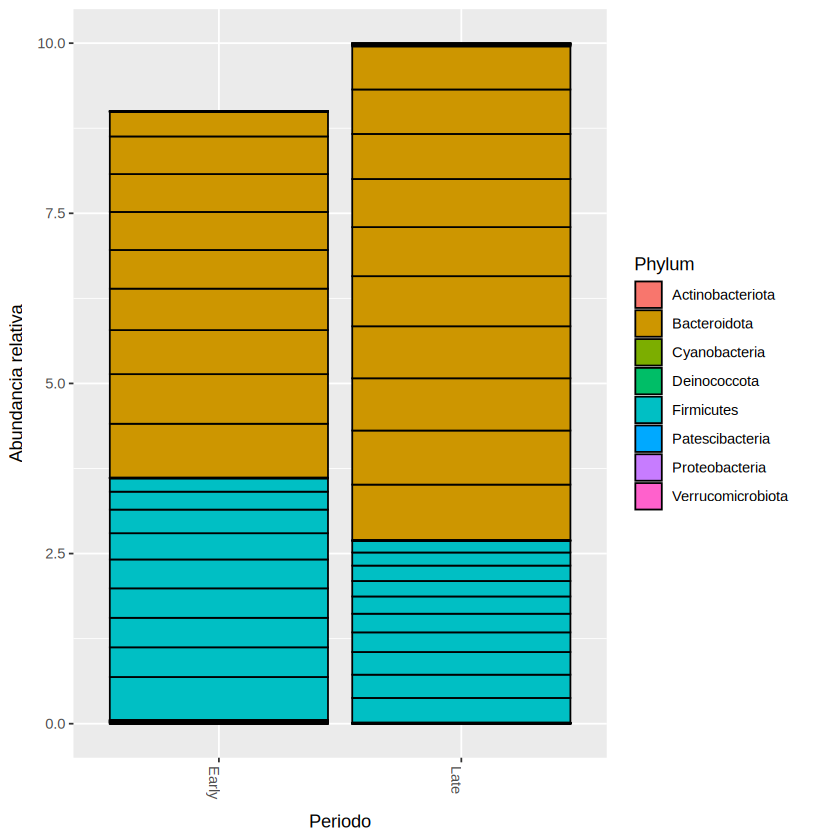

In [5]:
ps_rel <- transform_sample_counts(ps, function(x) x / sum(x))
ps_filo <- tax_glom(ps_rel, taxrank = "Phylum")
plot_bar(ps_filo, x = "Periodo", fill = "Phylum") +
  labs(x = "Periodo", y = "Abundancia relativa")

**Pregunta 3.** ¿Qué filos predominan? ¿Por qué las abundancias relativas se expresan como proporciones?

## 5. Diversidad alfa: Observed y Shannon
Los índices se calculan a partir de los conteos originales, no de la tabla transformada a proporciones.

Warning message in estimate_richness(ps, measures = c("Observed", "Shannon")):
“The data you have provided does not have
any singletons. This is highly suspicious. Results of richness
estimates (for example) are probably unreliable, or wrong, if you have already
trimmed low-abundance taxa from the data.

We recommended that you find the un-trimmed data and retry.”


,Observed,Shannon,Periodo
,<dbl>,<dbl>,<chr>
F3D0_S188_L001,106,3.865881,Early
F3D1_S189_L001,100,3.993196,Early
F3D141_S207_L001,74,3.428895,Late
F3D142_S208_L001,48,3.117940,Late
F3D143_S209_L001,56,3.293249,Late
F3D144_S210_L001,48,3.011652,Late



Early  Late 
    9    10 

Warning message in estimate_richness(physeq, split = TRUE, measures = measures):
“The data you have provided does not have
any singletons. This is highly suspicious. Results of richness
estimates (for example) are probably unreliable, or wrong, if you have already
trimmed low-abundance taxa from the data.

We recommended that you find the un-trimmed data and retry.”


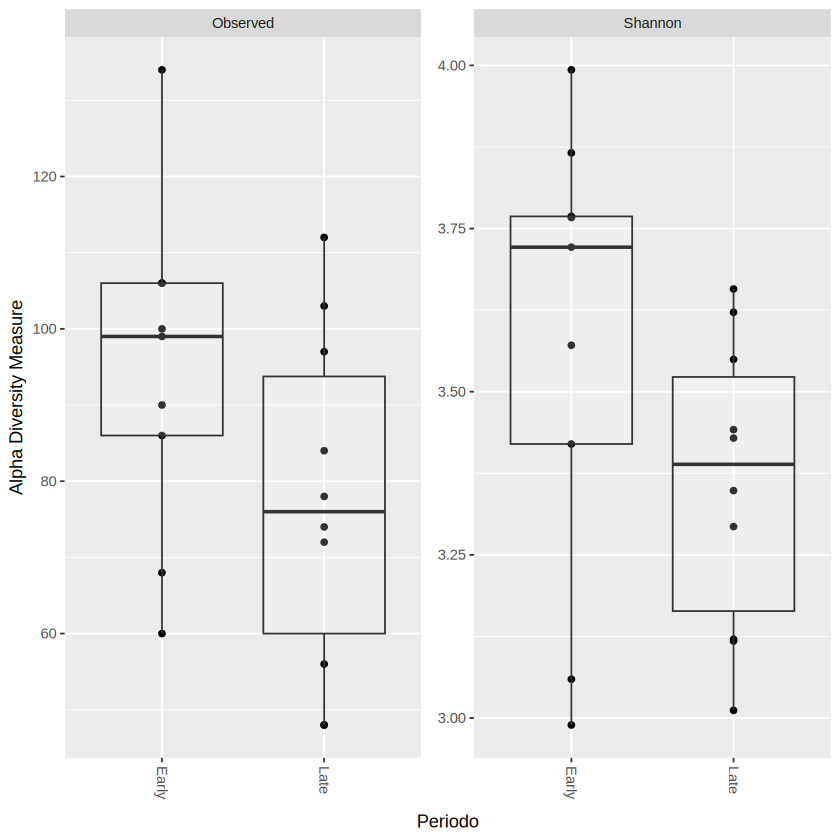

In [30]:
# Calcular diversidad alfa
alfa <- estimate_richness(ps,
                          measures = c("Observed", "Shannon"))

# Incorporar los metadatos
alfa$Periodo <- as.character(
  sample_data(ps)$Periodo[match(rownames(alfa), sample_names(ps))]
)

# Revisar resultados
head(alfa)
table(alfa$Periodo)

plot_richness(ps, x = "Periodo", measures = c("Observed", "Shannon")) +
  geom_boxplot(alpha = 0.2)

**Pregunta 4.** ¿Qué diferencia existe entre riqueza observada y Shannon? ¿Un gráfico por sí solo demuestra diferencias significativas?

### 5.1 Diversidad alfa con `ggpubr` y valor p

`ggpubr` permite añadir una comparación estadística directamente con `stat_compare_means()`.



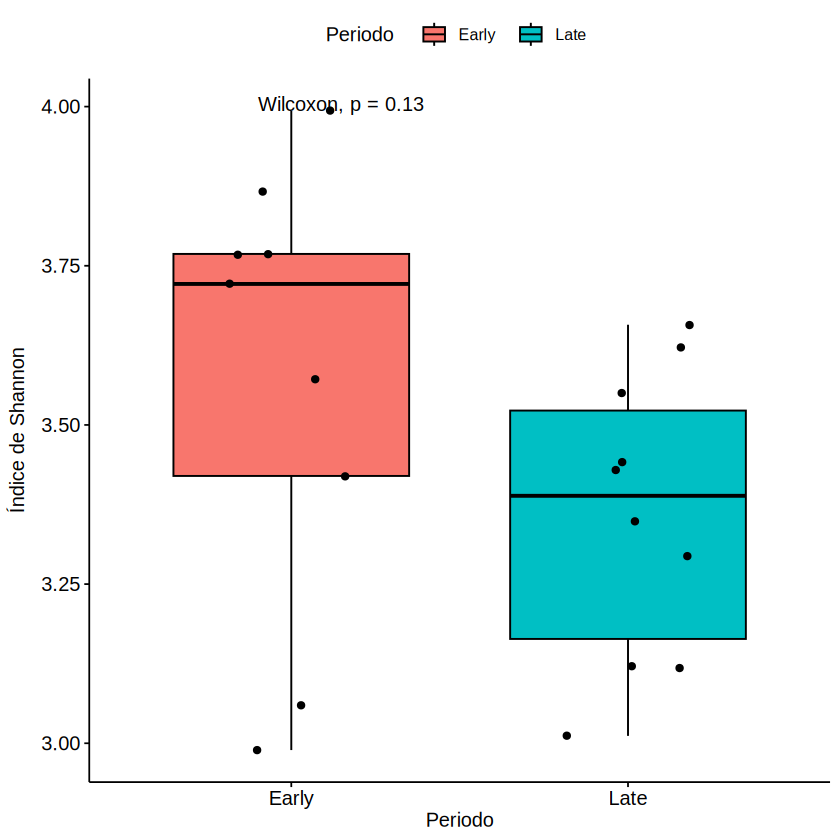

In [32]:
# Boxplot de Shannon
p_shannon <- ggboxplot(alfa, x = "Periodo", y = "Shannon",
                       fill = "Periodo", add = "jitter") +
  labs(x = "Periodo", y = "Índice de Shannon")

  p_shannon <- p_shannon + stat_compare_means()

p_shannon

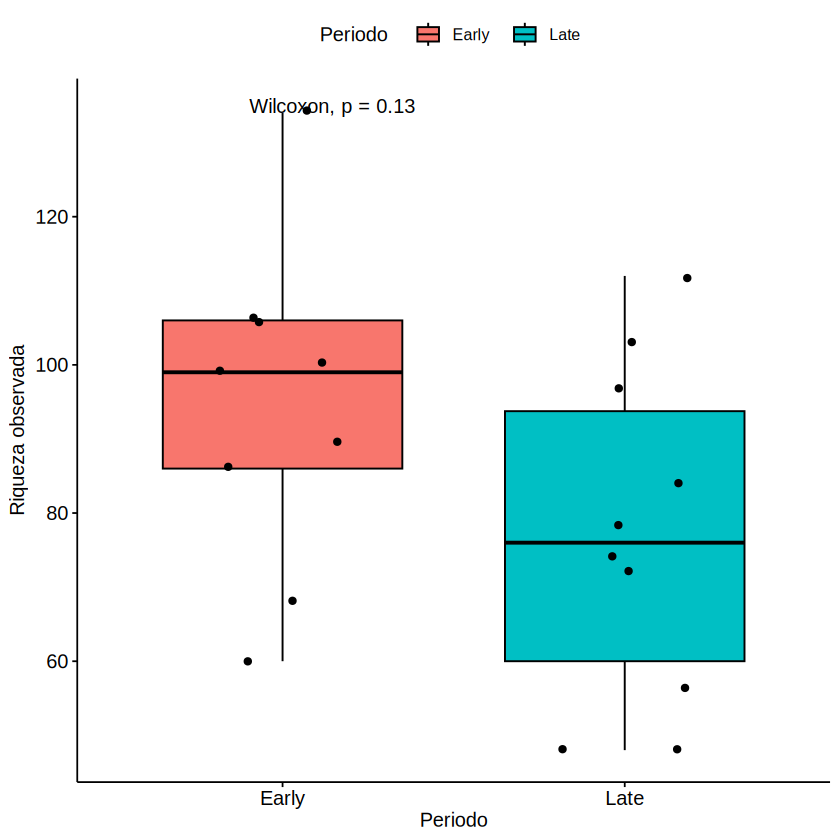

In [36]:
# Boxplot de riqueza observada
p_observed <- ggboxplot(alfa, x = "Periodo", y = "Observed",
                        fill = "Periodo", add = "jitter") +
  labs(x = "Periodo", y = "Riqueza observada")

  p_observed <- p_observed + stat_compare_means()

p_observed

**Pregunta 4B.** Compara las medianas de Observed y Shannon. ¿Por qué el gráfico no muestra un valor p por defecto? Si la docente confirma independencia, activa `muestras_independientes <- TRUE` y explica qué indica el valor p. Recuerda que p ≥ 0,05 no demuestra igualdad.

## 6. Diversidad beta: PCoA de Bray–Curtis

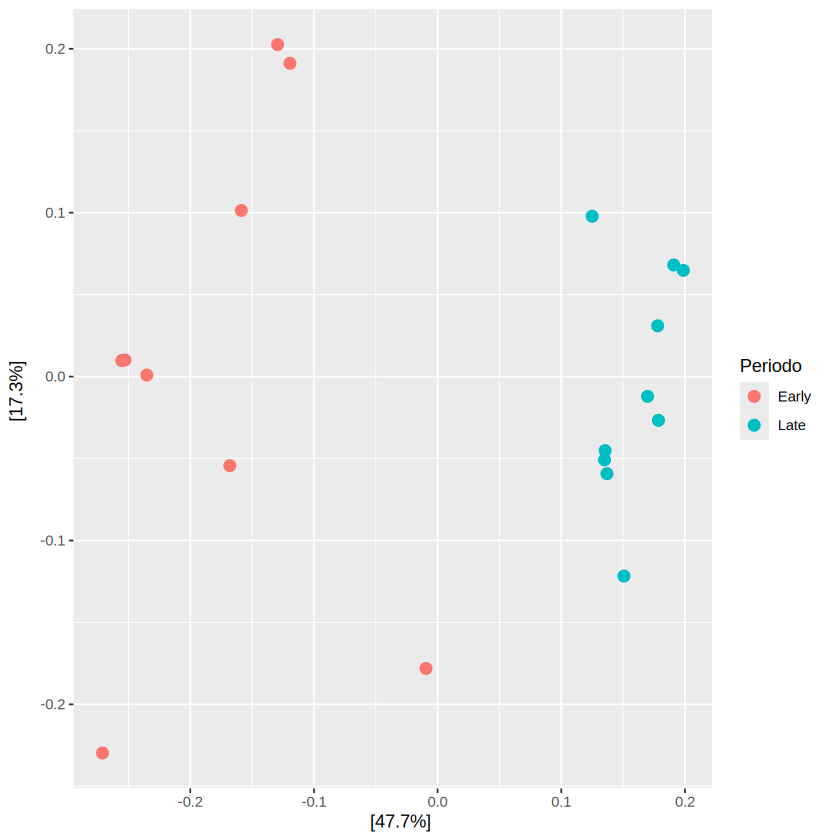

In [10]:
bray <- distance(ps_rel, method = "bray")
pcoa <- ordinate(ps_rel, method = "PCoA", distance = bray)
plot_ordination(ps_rel, pcoa, color = "Periodo") +
  geom_point(size = 3)

**Pregunta 5.** ¿Las muestras Early y Late se separan visualmente? ¿Qué significa que dos puntos estén próximos?

## 7. Visualización exploratoria de géneros bacterianos
**Actividad descriptiva (sin pruebas estadísticas).** Compararemos las abundancias relativas de géneros específicos entre Early y Late. Como los identificadores individuales no permiten establecer pares biológicos confiables, **no aplicaremos Wilcoxon ni hablaremos de abundancia diferencial significativa**.

### 7.1 Agrupar ASV a nivel de género

In [11]:
ps_genero <- tax_glom(ps, taxrank = "Genus", NArm = TRUE)
ps_genero <- transform_sample_counts(ps_genero, function(x) x / sum(x))
datos <- psmelt(ps_genero)
head(datos[, c("Sample", "Periodo", "Genus", "Abundance")])

,Sample,Periodo,Genus,Abundance
,<chr>,<fct>,<chr>,<dbl>
365,F3D1_S189_L001,Early,Lachnospiraceae NK4A136 group,0.3864656
370,F3D0_S188_L001,Early,Lachnospiraceae NK4A136 group,0.3707539
369,F3D5_S193_L001,Early,Lachnospiraceae NK4A136 group,0.3664717
65,F3D7_S195_L001,Early,Bacteroides,0.3663289
714,F3D144_S210_L001,Late,Lactobacillus,0.3084862
371,F3D2_S190_L001,Early,Lachnospiraceae NK4A136 group,0.3001381


### 7.2 Identificar los géneros más abundantes
Seleccionamos un género presente en los datos, en lugar de elegirlo por un valor p.

In [12]:
generos <- aggregate(Abundance ~ Genus, data = datos, FUN = mean)
generos <- generos[order(generos$Abundance, decreasing = TRUE), ]
head(generos, 10)

,Genus,Abundance
,<chr>,<dbl>
30,Lachnospiraceae NK4A136 group,0.20672824
11,Bacteroides,0.17540021
7,Alistipes,0.13153263
35,Lactobacillus,0.09537075
36,Ligilactobacillus,0.05487015
42,Turicibacter,0.04537998
38,Oscillibacter,0.03549165
40,Roseburia,0.03386839
28,Lachnoclostridium,0.03159421


### 7.3 Visualizar un género concreto
Seleccionamos el género con mayor abundancia relativa media entre las muestras. El título indicará su nombre.

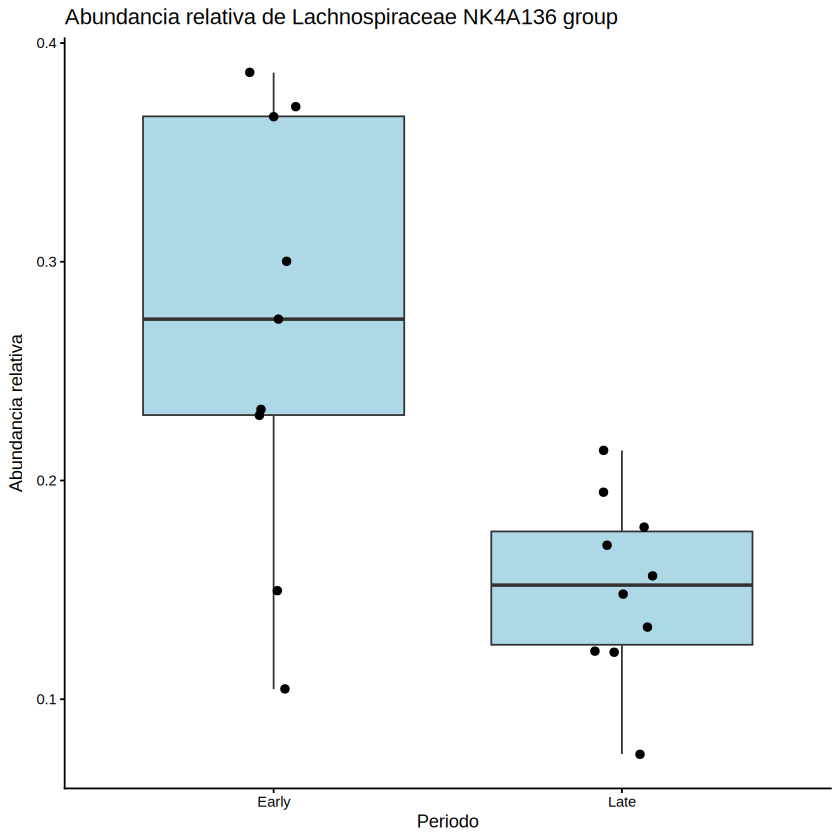

In [13]:
genero_ejemplo <- as.character(generos$Genus[1])
datos_genero <- subset(datos, Genus == genero_ejemplo)

ggplot(datos_genero, aes(x = Periodo, y = Abundance)) +
  geom_boxplot(fill = "lightblue") +
  geom_jitter(width = 0.1, size = 2) +
  labs(title = paste("Abundancia relativa de", genero_ejemplo),
       x = "Periodo", y = "Abundancia relativa") +
  theme_classic()

**Pregunta 6.** ¿Qué género se muestra? ¿En qué periodo se observa una mediana mayor? ¿Hay variabilidad entre muestras? ¿Por qué no podemos afirmar una diferencia estadísticamente significativa a partir de este gráfico?

### 7.4 Explorar otro género (opcional)
Reemplaza el número `1` por `2` o `3` para visualizar otro de los géneros más abundantes.

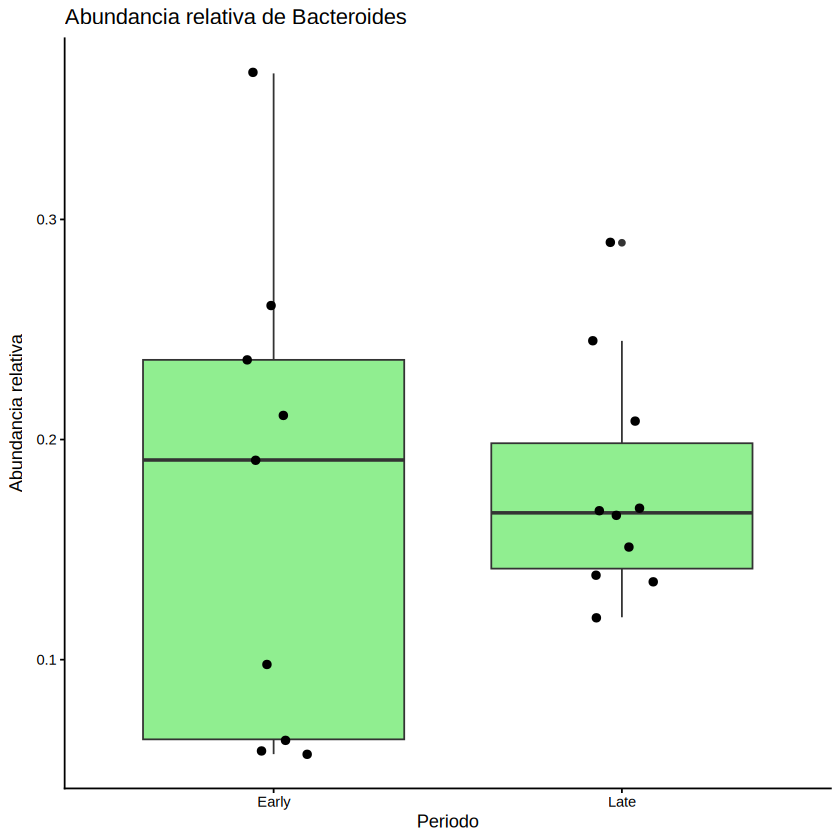

In [14]:
genero_ejemplo <- as.character(generos$Genus[2])
datos_genero <- subset(datos, Genus == genero_ejemplo)

ggplot(datos_genero, aes(x = Periodo, y = Abundance)) +
  geom_boxplot(fill = "lightgreen") +
  geom_jitter(width = 0.1, size = 2) +
  labs(title = paste("Abundancia relativa de", genero_ejemplo),
       x = "Periodo", y = "Abundancia relativa") +
  theme_classic()

## 8. Cierre del práctico
Redacta 5–7 líneas describiendo: (a) los filos predominantes, (b) diversidad alfa, (c) agrupamiento en la PCoA y (d) el patrón observado en uno de los géneros. **Distingue observación descriptiva de evidencia estadística.**